# Multi-View Breast Cancer Detection Prototype (PyTorch)
A dual-input CNN architecture with a shared DenseNet121 encoder, plus a matched-backbone single-view vs multi-view ablation.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
print('torch:', torch.__version__)
print('torch cuda build:', torch.version.cuda)
print('cuda available:', torch.cuda.is_available())
print('device:', device)
if torch.cuda.is_available():
    print('cuda device name:', torch.cuda.get_device_name(0))


torch: 2.6.0+cu124
torch cuda build: 12.4
cuda available: True
device: cuda
cuda device name: NVIDIA GeForce RTX 3070


In [3]:
torch.manual_seed(42)
np.random.seed(42)

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])


In [5]:
# Single-View Baseline CNN — backbone: 'resnet50', 'densenet121', or 'efficientnet'
class SingleViewCNN(nn.Module):
    def __init__(self, backbone='resnet50'):
        super().__init__()
        if backbone == 'resnet50':
            net = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            self.encoder = nn.Sequential(*list(net.children())[:-1])
            feat_size = 2048
        elif backbone == 'densenet121':
            net = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
            self.encoder = nn.Sequential(net.features, nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1)))
            feat_size = 1024
        elif backbone == 'efficientnet':
            net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            self.encoder = nn.Sequential(net.features, net.avgpool)
            feat_size = 1280
        else:
            raise ValueError(f"Unknown backbone: {backbone!r}")
        self.classifier = nn.Sequential(nn.Linear(feat_size, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 2))

    def forward(self, x):
        x = self.encoder(x).flatten(1)
        return self.classifier(x)

single_model = SingleViewCNN(backbone='densenet121').to(device)
# Lower lr for pretrained backbone, higher lr for new classifier head
optimizer_single = torch.optim.Adam([
    {'params': single_model.encoder.parameters(), 'lr': 1e-5},
    {'params': single_model.classifier.parameters(), 'lr': 1e-4},
])
criterion = nn.CrossEntropyLoss()  # overridden with class weights after data loading


In [6]:
class MultiViewDataset(Dataset):
    def __init__(self, csv_file=None, transform=None, df=None):
        self.df = df if df is not None else pd.read_csv(csv_file)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        cc_path = row['cc_path']
        mlo_path = row['mlo_path']
        cc = Image.open(cc_path).convert('RGB')
        mlo = Image.open(mlo_path).convert('RGB')
        y = int(row['label'])
        if self.transform:
            cc = self.transform(cc)
            mlo = self.transform(mlo)
        return cc, mlo, y


In [7]:
# CBIS-DDSM dataset
DATA_ROOT = Path.cwd()
if not (DATA_ROOT / 'archive').exists() and (DATA_ROOT / 'FYP' / 'archive').exists():
    DATA_ROOT = DATA_ROOT / 'FYP'
CSV_ROOT = DATA_ROOT / 'archive' / 'csv'

def build_shared_dataframe(case_csv):
    if not case_csv.exists():
        print(f"Warning: {case_csv} not found")
        return pd.DataFrame(columns=['cc_path', 'mlo_path', 'label'])
    cases = pd.read_csv(case_csv).copy()
    cases['case_id_full'] = cases['image file path'].astype(str).str.split('/', n=1).str[0]
    cases['case_key'] = cases['case_id_full'].str.rsplit('_', n=1).str[0]
    cases['view'] = cases['image view'].astype(str).str.strip().str.upper()
    cases['label'] = cases['pathology'].astype(str).str.upper().eq('MALIGNANT').astype(int)
    cases = cases[cases['view'].isin(['CC', 'MLO'])].copy()
    dicom_map = pd.read_csv(CSV_ROOT / 'dicom_info.csv')[['PatientID', 'SeriesDescription', 'image_path']]
    dicom_map = dicom_map[dicom_map['SeriesDescription'].eq('full mammogram images')].copy()
    merged = cases.merge(dicom_map, left_on='case_id_full', right_on='PatientID', how='left')
    merged = merged.dropna(subset=['image_path'])
    merged['image_path'] = merged['image_path'].apply(lambda p: str(DATA_ROOT / 'archive' / p.replace('CBIS-DDSM/', '')))
    pivoted = merged.pivot_table(
        index=['case_key', 'label'],
        columns='view',
        values='image_path',
        aggfunc='first'
    ).reset_index()
    pivoted.columns.name = None
    if 'CC' not in pivoted.columns or 'MLO' not in pivoted.columns:
        raise ValueError(f"No CC/MLO pairs found for {case_csv.name}; verify image view labels and dicom_info.csv.")
    result = pivoted[['CC', 'MLO', 'label']].dropna(subset=['CC', 'MLO']).copy()
    result = result.rename(columns={'CC': 'cc_path', 'MLO': 'mlo_path'})
    if result.empty:
        raise ValueError(f"No paired CC/MLO samples found for {case_csv.name}; check your mapping logic.")
    sample_path = Path(result.iloc[0]['cc_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved CC path does not exist: {sample_path}")
    sample_path = Path(result.iloc[0]['mlo_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved MLO path does not exist: {sample_path}")
    print(f"Loaded {len(result)} CC/MLO pairs from {case_csv.name}")
    return result


train_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_train_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_train_set.csv'),
], ignore_index=True)

test_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_test_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_test_set.csv'),
], ignore_index=True)

# Hold out a stratified validation split from the training cases (test set stays untouched)
train_pairs, val_pairs = train_test_split(
    train_pairs, test_size=0.15, stratify=train_pairs['label'], random_state=42
)

train_dataset = MultiViewDataset(df=train_pairs, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

val_dataset = MultiViewDataset(df=val_pairs, transform=val_transform)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

test_dataset = MultiViewDataset(df=test_pairs, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Class-weighted loss to handle benign/malignant imbalance (computed on the training split only)
counts = train_pairs['label'].value_counts().sort_index()
class_weights = torch.tensor([1.0 / counts[0], 1.0 / counts[1]], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print(f"Train/Val split: {len(train_pairs)} train, {len(val_pairs)} val, {len(test_pairs)} test")
print(f"Class weights — Benign: {class_weights[0]:.4f}, Malignant: {class_weights[1]:.4f}")

Loaded 568 CC/MLO pairs from calc_case_description_train_set.csv
Loaded 512 CC/MLO pairs from mass_case_description_train_set.csv
Loaded 5 CC/MLO pairs from calc_case_description_test_set.csv
Loaded 151 CC/MLO pairs from mass_case_description_test_set.csv
Train/Val split: 918 train, 162 val, 156 test
Class weights — Benign: 0.0020, Malignant: 0.0024


In [8]:
def collect_single_view(loader, mdl, view='cc'):
    mdl.eval()
    labels, preds, probs = [], [], []
    with torch.no_grad():
        for cc, mlo, y in loader:
            x = cc.to(device) if view == 'cc' else mlo.to(device)
            logits = mdl(x)
            prob = torch.softmax(logits, dim=1)[:, 1]
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            probs.extend(prob.cpu().numpy())
            labels.extend(y.numpy())
    return np.array(labels), np.array(preds), np.array(probs)

def collect_multi_view(loader, mdl):
    mdl.eval()
    labels, preds, probs = [], [], []
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, mlo = cc.to(device), mlo.to(device)
            logits = mdl(cc, mlo)
            prob = torch.softmax(logits, dim=1)[:, 1]
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            probs.extend(prob.cpu().numpy())
            labels.extend(y.numpy())
    return np.array(labels), np.array(preds), np.array(probs)

def metrics_from_scores(labels, preds, probs):
    return (
        accuracy_score(labels, preds),
        precision_score(labels, preds, average='macro', zero_division=0),
        recall_score(labels, preds, average='macro', zero_division=0),
        f1_score(labels, preds, average='macro', zero_division=0),
        roc_auc_score(labels, probs),
    )

In [9]:
def train_single(loader):
    single_model.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, y = cc.to(device), y.to(device)
        optimizer_single.zero_grad()
        out = single_model(cc)
        loss = criterion(out, y)
        loss.backward()
        optimizer_single.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def val_loss_single(loader):
    single_model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, y = cc.to(device), y.to(device)
            loss = criterion(single_model(cc), y)
            total_loss += loss.item()
    return total_loss / len(loader)

def evaluate_single(loader):
    labels, preds, probs = collect_single_view(loader, single_model, view='cc')
    return metrics_from_scores(labels, preds, probs)

In [10]:
# Multi-View DenseNet121 Model
class MultiViewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        self.encoder = nn.Sequential(backbone.features, nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Linear(2048,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,2)
        )
    def forward(self, cc, mlo):
        cc = self.encoder(cc).flatten(1)
        mlo = self.encoder(mlo).flatten(1)
        x = torch.cat([cc, mlo], dim=1)
        return self.classifier(x)

model = MultiViewCNN().to(device)


In [11]:
optimizer_multi = torch.optim.Adam(model.parameters(), lr=1e-4)


def train_epoch(loader, mdl=model, optimizer=optimizer_multi):
    mdl.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        optimizer.zero_grad()
        out = mdl(cc, mlo)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def val_loss_multi(loader, mdl=model):
    mdl.eval()
    total_loss = 0.0
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
            loss = criterion(mdl(cc, mlo), y)
            total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(loader, mdl=model):
    mdl.eval()
    preds = []
    labels = []
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, mlo = cc.to(device), mlo.to(device)
            out = mdl(cc, mlo)
            pred = torch.argmax(out, 1).cpu().numpy()
            preds.extend(pred)
            labels.extend(y.numpy())
    return accuracy_score(labels, preds)


def train_single_view(loader, mdl, optimizer, view='cc'):
    mdl.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        x = cc.to(device) if view == 'cc' else mlo.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        out = mdl(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate_single_view(loader, mdl, view='cc'):
    labels, preds, probs = collect_single_view(loader, mdl, view=view)
    return metrics_from_scores(labels, preds, probs)

Epoch 1: Single Train Loss=0.6993 | Val Loss=0.7028
Epoch 2: Single Train Loss=0.6771 | Val Loss=0.6744
Epoch 3: Single Train Loss=0.6677 | Val Loss=0.6634

Single-View Results:
  Accuracy:  0.6538
  Precision: 0.6399
  Recall:    0.6414
  F1 Score:  0.6406
  ROC-AUC:   0.6422


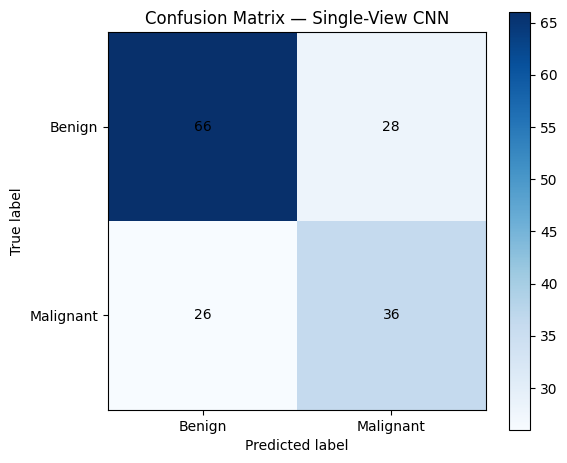

In [12]:
EPOCHS = 3
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_single, T_max=EPOCHS)

single_losses = []
single_val_losses = []
for e in range(EPOCHS):
    single_loss = train_single(train_loader)
    single_val_loss = val_loss_single(val_loader)
    single_losses.append(single_loss)
    single_val_losses.append(single_val_loss)
    scheduler.step()
    print(f'Epoch {e+1}: Single Train Loss={single_loss:.4f} | Val Loss={single_val_loss:.4f}')

labels_sv, preds_sv, probs_sv = collect_single_view(test_loader, single_model, view='cc')
acc, prec, rec, f1, auc = metrics_from_scores(labels_sv, preds_sv, probs_sv)
print(f"\nSingle-View Results:")
print(f"  Accuracy:  {acc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1 Score:  {f1:.4f}")
print(f"  ROC-AUC:   {auc:.4f}")

cm_sv = confusion_matrix(labels_sv, preds_sv)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_sv, cmap='Blues')
for i in range(cm_sv.shape[0]):
    for j in range(cm_sv.shape[1]):
        ax.text(j, i, cm_sv[i, j], ha='center', va='center', color='black')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Benign', 'Malignant'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Benign', 'Malignant'])
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix — Single-View CNN')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [14]:
multi_losses = []
multi_val_losses = []
for e in range(EPOCHS):
    multi_loss = train_epoch(train_loader)
    multi_val_loss = val_loss_multi(val_loader)
    multi_losses.append(multi_loss)
    multi_val_losses.append(multi_val_loss)
    print(f'Epoch {e+1}: Multi Train Loss={multi_loss:.4f} | Val Loss={multi_val_loss:.4f}')

labels_mv, preds_mv, probs_mv = collect_multi_view(test_loader, model)
acc_mv, prec_mv, rec_mv, f1_mv, auc_mv = metrics_from_scores(labels_mv, preds_mv, probs_mv)
print(f"\nMulti-View Results:")
print(f"  Accuracy:  {acc_mv:.4f}")
print(f"  Precision: {prec_mv:.4f}")
print(f"  Recall:    {rec_mv:.4f}")
print(f"  F1 Score:  {f1_mv:.4f}")
print(f"  ROC-AUC:   {auc_mv:.4f}")

cm = confusion_matrix(labels_mv, preds_mv)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Benign', 'Malignant'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Benign', 'Malignant'])
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix — Multi-View CNN')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, EPOCHS + 1), single_losses, marker='o', label='Single-View Train Loss')
ax.plot(range(1, EPOCHS + 1), single_val_losses, marker='o', linestyle='--', label='Single-View Val Loss')
ax.plot(range(1, EPOCHS + 1), multi_losses, marker='s', label='Multi-View Train Loss')
ax.plot(range(1, EPOCHS + 1), multi_val_losses, marker='s', linestyle='--', label='Multi-View Val Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training vs Validation Loss Curve')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

Epoch 1: Multi Train Loss=0.6197 | Val Loss=0.6182
Epoch 2: Multi Train Loss=0.5901 | Val Loss=0.5678


MemoryError: 

In [ ]:
main_results_df = pd.DataFrame(
    [
        ('Single-view CNN', acc, prec, rec, f1, auc),
        ('Multi-view CNN', acc_mv, prec_mv, rec_mv, f1_mv, auc_mv),
    ],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
).set_index('Model').round(4)

print('=== Main Results: Single-View vs Multi-View ===')
print(main_results_df.to_string())

In [ ]:
fpr_sv, tpr_sv, _ = roc_curve(labels_sv, probs_sv)
fpr_mv, tpr_mv, _ = roc_curve(labels_mv, probs_mv)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr_sv, tpr_sv, label=f'Single-View CNN (AUC={auc:.3f})')
ax.plot(fpr_mv, tpr_mv, label=f'Multi-View CNN (AUC={auc_mv:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Single-View vs Multi-View')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
single_scores = [acc, prec, rec, f1, auc]
multi_scores = [acc_mv, prec_mv, rec_mv, f1_mv, auc_mv]

x = np.arange(len(metric_names))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, single_scores, width, label='Single-View CNN')
ax.bar(x + width / 2, multi_scores, width, label='Multi-View CNN')
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Single-View vs Multi-View — Metric Comparison')
ax.legend()
plt.tight_layout()
plt.show()

print('=== Single-view vs Multi-view discussion ===')
deltas = {name: mv - sv for name, sv, mv in zip(metric_names, single_scores, multi_scores)}
direction = 'improves on' if deltas['ROC-AUC'] > 0 else 'does not improve on'
print(f"The multi-view CNN {direction} the single-view CNN on ROC-AUC (Δ={deltas['ROC-AUC']:+.4f}).")
for name in metric_names:
    print(f"  Δ{name}: {deltas[name]:+.4f} (multi-view − single-view)")

In [ ]:
import torch.nn.functional as F

def distillation_loss(student_logits, teacher_logits, labels, T=4.0, alpha=0.5):
    soft_student = F.log_softmax(student_logits / T, dim=1)
    soft_teacher = F.softmax(teacher_logits / T, dim=1)
    # scale by T^2 to keep gradient magnitudes consistent with CE loss
    kd_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (T ** 2)
    return alpha * criterion(student_logits, labels) + (1 - alpha) * kd_loss

def train_distilled(student, opt, loader, get_teacher_logits, T=4.0, alpha=0.5):
    student.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        opt.zero_grad()
        with torch.no_grad():
            teacher_logits = get_teacher_logits(cc, mlo)
        loss = distillation_loss(student(cc), teacher_logits, y, T, alpha)
        loss.backward()
        opt.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def eval_sv(mdl, loader):
    labels, preds, probs = collect_single_view(loader, mdl, view='cc')
    return metrics_from_scores(labels, preds, probs)

def eval_mv(mdl, loader):
    labels, preds, probs = collect_multi_view(loader, mdl)
    return metrics_from_scores(labels, preds, probs)

In [ ]:
# Matched-backbone ablation: same DenseNet121 backbone, same data, only the view setup changes.
# This isolates the contribution of using CC+MLO jointly without changing the architecture.

single_cc_model = SingleViewCNN(backbone='densenet121').to(device)
single_mlo_model = SingleViewCNN(backbone='densenet121').to(device)

optimizer_cc = torch.optim.Adam([
    {'params': single_cc_model.encoder.parameters(), 'lr': 1e-5},
    {'params': single_cc_model.classifier.parameters(), 'lr': 1e-4},
])
optimizer_mlo = torch.optim.Adam([
    {'params': single_mlo_model.encoder.parameters(), 'lr': 1e-5},
    {'params': single_mlo_model.classifier.parameters(), 'lr': 1e-4},
])

cc_ablation_losses = []
mlo_ablation_losses = []
for e in range(EPOCHS):
    cc_loss = train_single_view(train_loader, single_cc_model, optimizer_cc, view='cc')
    mlo_loss = train_single_view(train_loader, single_mlo_model, optimizer_mlo, view='mlo')
    cc_ablation_losses.append(cc_loss)
    mlo_ablation_losses.append(mlo_loss)
    print(f'Epoch {e+1}: CC-only Loss={cc_loss:.4f} | MLO-only Loss={mlo_loss:.4f}')

print('\n=== Fair matched-backbone ablation ===')
ablation_summary = {
    'Single-view CC (DenseNet121)': evaluate_single_view(test_loader, single_cc_model, view='cc'),
    'Single-view MLO (DenseNet121)': evaluate_single_view(test_loader, single_mlo_model, view='mlo'),
    'Multi-view Shared DenseNet121': eval_mv(model, test_loader),
}
ablation_df = pd.DataFrame(
    [(name,) + metrics for name, metrics in ablation_summary.items()],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
).set_index('Model').round(4)
print(ablation_df.to_string())

## Knowledge Distillation & Cross-Architecture Transfer
## - **Multi-View → ResNet50**: multi-view model acts as teacher to improve single-view ResNet50
## - **ResNet50 → DenseNet121 / EfficientNet**: cross-architecture distillation using the trained ResNet50 as teacher

In [ ]:
model.eval()
distilled_resnet = SingleViewCNN(backbone='resnet50').to(device)
opt_dr = torch.optim.Adam([
    {'params': distilled_resnet.encoder.parameters(), 'lr': 1e-5},
    {'params': distilled_resnet.classifier.parameters(), 'lr': 1e-4},
])
sched_dr = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dr, T_max=EPOCHS)

print("=== Distillation: Multi-View Teacher → ResNet50 Student ===")
for e in range(EPOCHS):
    loss = train_distilled(distilled_resnet, opt_dr, train_loader,
                           get_teacher_logits=lambda cc, mlo: model(cc, mlo))
    sched_dr.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_dr, prec_dr, rec_dr, f1_dr, auc_dr = eval_sv(distilled_resnet, test_loader)
print(f"\nDistilled ResNet50 (Multi-View Teacher):")
print(f"  Acc={acc_dr:.4f} | Prec={prec_dr:.4f} | Rec={rec_dr:.4f} | F1={f1_dr:.4f} | AUC={auc_dr:.4f}")

=== Distillation: Multi-View Teacher → ResNet50 Student ===
Epoch 1: Loss=0.4059
Epoch 2: Loss=0.3925
Epoch 3: Loss=0.3800

Distilled ResNet50 (Multi-View Teacher):
  Acc=0.5577 | Prec=0.4935 | Rec=0.4957 | F1=0.4715


In [ ]:
single_model.eval()

# ResNet50 → DenseNet121
densenet_student = SingleViewCNN(backbone='densenet121').to(device)
opt_dn = torch.optim.Adam([
    {'params': densenet_student.encoder.parameters(), 'lr': 1e-5},
    {'params': densenet_student.classifier.parameters(), 'lr': 1e-4},
])
sched_dn = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dn, T_max=EPOCHS)

print("=== Cross-Architecture: ResNet50 Teacher → DenseNet121 Student ===")
for e in range(EPOCHS):
    loss = train_distilled(densenet_student, opt_dn, train_loader,
                           get_teacher_logits=lambda cc, mlo: single_model(cc))
    sched_dn.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_dn, prec_dn, rec_dn, f1_dn, auc_dn = eval_sv(densenet_student, test_loader)
print(f"\nDistilled DenseNet121: Acc={acc_dn:.4f} | Prec={prec_dn:.4f} | Rec={rec_dn:.4f} | F1={f1_dn:.4f} | AUC={auc_dn:.4f}")

# ResNet50 → EfficientNet
effnet_student = SingleViewCNN(backbone='efficientnet').to(device)
opt_en = torch.optim.Adam([
    {'params': effnet_student.encoder.parameters(), 'lr': 1e-5},
    {'params': effnet_student.classifier.parameters(), 'lr': 1e-4},
])
sched_en = torch.optim.lr_scheduler.CosineAnnealingLR(opt_en, T_max=EPOCHS)

print("\n=== Cross-Architecture: ResNet50 Teacher → EfficientNet Student ===")
for e in range(EPOCHS):
    loss = train_distilled(effnet_student, opt_en, train_loader,
                           get_teacher_logits=lambda cc, mlo: single_model(cc))
    sched_en.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_en, prec_en, rec_en, f1_en, auc_en = eval_sv(effnet_student, test_loader)
print(f"\nDistilled EfficientNet: Acc={acc_en:.4f} | Prec={prec_en:.4f} | Rec={rec_en:.4f} | F1={f1_en:.4f} | AUC={auc_en:.4f}")

=== Cross-Architecture: ResNet50 Teacher → DenseNet121 Student ===
Epoch 1: Loss=0.3577
Epoch 2: Loss=0.3358
Epoch 3: Loss=0.3307

Distilled DenseNet121: Acc=0.5513 | Prec=0.5340 | Rec=0.5343 | F1=0.5341


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Enzo/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100.0%



=== Cross-Architecture: ResNet50 Teacher → EfficientNet Student ===
Epoch 1: Loss=0.3551
Epoch 2: Loss=0.3428
Epoch 3: Loss=0.3402

Distilled EfficientNet: Acc=0.5897 | Prec=0.5407 | Rec=0.5251 | F1=0.5003


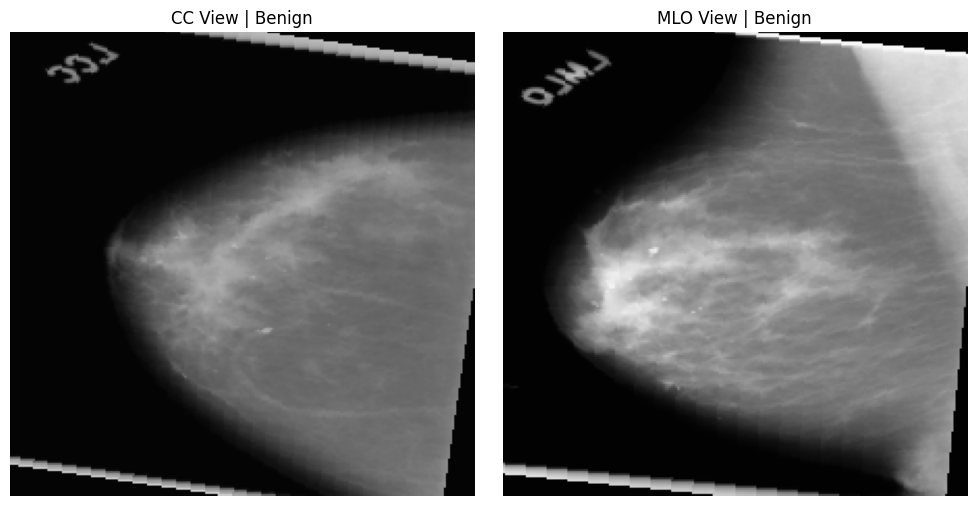

In [ ]:
sample_idx = np.random.randint(len(train_dataset))
sample_cc, sample_mlo, sample_y = train_dataset[sample_idx]
sample_cc = sample_cc.mul(0.5).add(0.5).clamp(0, 1)
sample_mlo = sample_mlo.mul(0.5).add(0.5).clamp(0, 1)
label_text = 'Malignant' if sample_y == 1 else 'Benign'

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sample_cc.permute(1, 2, 0))
ax[0].set_title(f'CC View | {label_text}')
ax[0].axis('off')

ax[1].imshow(sample_mlo.permute(1, 2, 0))
ax[1].set_title(f'MLO View | {label_text}')
ax[1].axis('off')

plt.tight_layout()

In [ ]:
# Re-evaluates the main matched-backbone ablation and the distillation experiments separately.
# The fair comparison is kept distinct from the cross-architecture transfer results.

fair_summary_data = {
    'Single-view CC (DenseNet121)': evaluate_single_view(test_loader, single_cc_model, view='cc'),
    'Single-view MLO (DenseNet121)': evaluate_single_view(test_loader, single_mlo_model, view='mlo'),
    'Multi-view Shared DenseNet121': eval_mv(model, test_loader),
}

fair_summary_df = pd.DataFrame(
    [(name,) + metrics for name, metrics in fair_summary_data.items()],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
).set_index('Model').round(4)

print('=== Fair matched-backbone comparison ===')
print(fair_summary_df.to_string())

print('\n=== Distillation / cross-architecture comparison ===')
distillation_summary_data = {
    'KD: Multi-View → ResNet50': eval_sv(distilled_resnet, test_loader),
    'KD: ResNet50 → DenseNet121': eval_sv(densenet_student, test_loader),
    'KD: ResNet50 → EfficientNet': eval_sv(effnet_student, test_loader),
}

distillation_summary_df = pd.DataFrame(
    [(name,) + metrics for name, metrics in distillation_summary_data.items()],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
).set_index('Model').round(4)
print(distillation_summary_df.to_string())

                             Accuracy  Precision  Recall      F1
Model                                                           
Single-View ResNet50           0.5705     0.5527  0.5530  0.5529
Multi-View CNN                 0.5962     0.6288  0.6265  0.5960
KD: Multi-View → ResNet50      0.5577     0.4935  0.4957  0.4715
KD: ResNet50 → DenseNet121     0.5513     0.5340  0.5343  0.5341
KD: ResNet50 → EfficientNet    0.5897     0.5407  0.5251  0.5003
